# Détection d'Anomalies IoT — Hybridation VAE + XGBoost

**Dataset :** N-BaIoT 2018 (Ben-Gurion University) — 7M flux réseau réels, 9 appareils IoT, 11 classes

**Approche hybride :**
1. **VAE** (Variational AutoEncoder) — extraction non supervisée de features latentes compactes (115D → 20D)
2. **XGBoost** — classification supervisée (binaire + multi-classe) sur l'espace latent

**Pipeline :** Chargement → Prétraitement robuste → VAE → Extraction μ → XGBoost → Évaluation

---

## 1. Imports et Configuration

In [ ]:
import os, gc, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_curve, auc)

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Lambda, Layer
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

import xgboost as xgb

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')


## 2. Chargement du Dataset

Chargement par chunks avec labels séparés pour éviter le `MemoryError` du `pd.concat` sur 7M lignes.

In [2]:
BASE_PATH = r'E:\detection+of+iot+botnet+attacks+n+baiot'

DEVICES = [
    'Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell',
    'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera',
    'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam',
    'SimpleHome_XCS7_1002_WHT_Security_Camera',
    'SimpleHome_XCS7_1003_WHT_Security_Camera',
]
GAFGYT = ['combo.csv', 'junk.csv', 'scan.csv', 'tcp.csv', 'udp.csv']
MIRAI  = ['ack.csv', 'scan.csv', 'syn.csv', 'udp.csv', 'udpplain.csv']
NO_MIRAI = ['Ennio_Doorbell', 'Samsung_SNH_1011_N_Webcam']

X_list, labels, devices_list = [], [], []
start = time.time()

for device in DEVICES:
    dpath = os.path.join(BASE_PATH, device)
    if not os.path.exists(dpath):
        continue

    # Liste (fichier, label, sous-dossier) à charger pour cet appareil
    todo = [('benign_traffic.csv', 'benign', '')]
    todo += [(f, f'gafgyt_{f[:-4]}', 'gafgyt_attacks') for f in GAFGYT]
    if device not in NO_MIRAI:
        todo += [(f, f'mirai_{f[:-4]}', 'mirai_attacks') for f in MIRAI]

    for fname, label, sub in todo:
        fpath = os.path.join(dpath, sub, fname) if sub else os.path.join(dpath, fname)
        if not os.path.exists(fpath):
            continue
        df = pd.read_csv(fpath)
        X_list.append(df.values.astype(np.float32))   # float32 = 2x moins de RAM
        labels.extend([label] * len(df))
        devices_list.extend([device] * len(df))
        del df; gc.collect()
    print(f'OK : {device}')

# Concaténation numérique (np.vstack) au lieu de pd.concat (évite MemoryError)
X_raw   = np.vstack(X_list)
y_raw   = np.array(labels)
devices = np.array(devices_list)
del X_list, labels, devices_list; gc.collect()

print(f'\nChargé en {time.time()-start:.0f}s | {X_raw.shape[0]:,} flux × {X_raw.shape[1]} features')

OK : Danmini_Doorbell
OK : Ecobee_Thermostat
OK : Ennio_Doorbell
OK : Philips_B120N10_Baby_Monitor
OK : Provision_PT_737E_Security_Camera
OK : Provision_PT_838_Security_Camera
OK : Samsung_SNH_1011_N_Webcam
OK : SimpleHome_XCS7_1002_WHT_Security_Camera
OK : SimpleHome_XCS7_1003_WHT_Security_Camera

Chargé en 234s | 7,062,606 flux × 115 features


## 3. Analyse Exploratoire

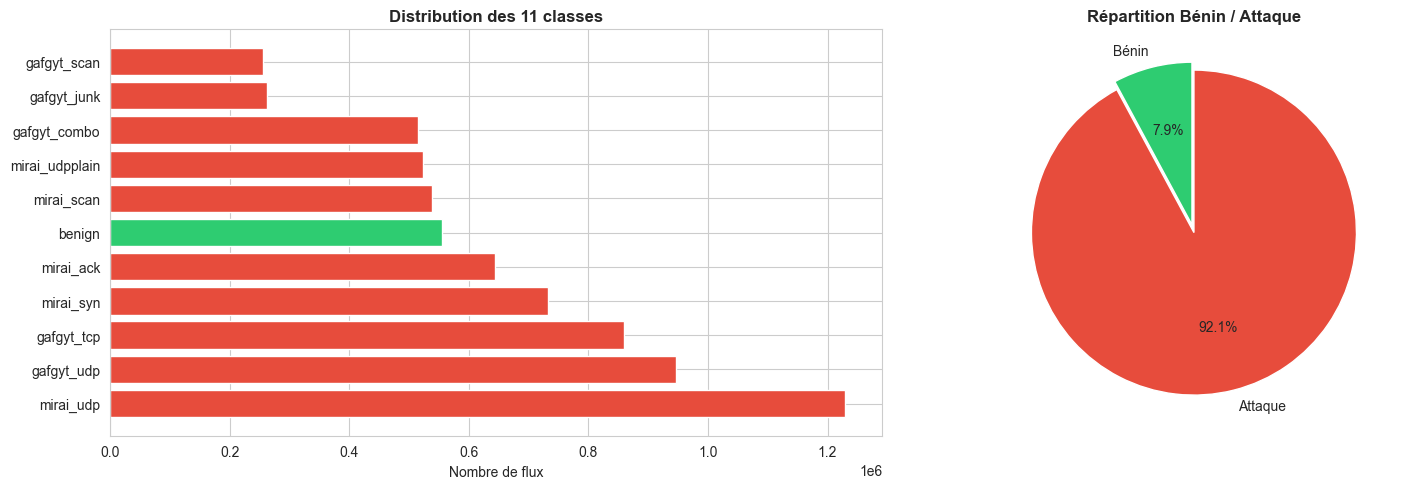

Bénin : 555,932 (7.87%)
Attaque : 6,506,674 (92.13%)


In [ ]:
# Distribution des 11 classes
classes, counts = np.unique(y_raw, return_counts=True)
order = np.argsort(counts)[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Barplot des classes
colors = ['#2ecc71' if c == 'benign' else '#e74c3c' for c in classes[order]]
ax1.barh(classes[order], counts[order], color=colors)
ax1.set_title('Distribution des 11 classes', fontweight='bold')
ax1.set_xlabel('Nombre de flux')

# Camembert binaire (bénin vs attaque)
n_benign = (y_raw == 'benign').sum()
n_attack = len(y_raw) - n_benign
ax2.pie([n_benign, n_attack], labels=['Bénin', 'Attaque'], autopct='%1.1f%%',
        colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0.05, 0))
ax2.set_title('Répartition Bénin / Attaque', fontweight='bold')

plt.tight_layout();
plt.savefig('01_distribution.png', dpi=150, bbox_inches='tight');
plt.show()

print(f'Bénin : {n_benign:,} ({n_benign/len(y_raw)*100:.2f}%)')
print(f'Attaque : {n_attack:,} ({n_attack/len(y_raw)*100:.2f}%)')

## 4. Prétraitement

Encodage des labels, split stratifié 80/20, puis normalisation robuste en 4 étapes (clip → log → scaler → clip).

In [4]:
# Nettoyage : Inf -> NaN -> suppression
X_raw[np.isinf(X_raw)] = np.nan
valid   = ~np.isnan(X_raw).any(axis=1)
X_raw, y_raw, devices = X_raw[valid], y_raw[valid], devices[valid]

# Encodage : binaire (0/1) + multi-classe (0->10)
y_bin = np.where(y_raw == 'benign', 0, 1).astype(np.int32)
le    = LabelEncoder()
y_mul = le.fit_transform(y_raw).astype(np.int32)

# Split stratifié 80/20
idx = np.arange(len(X_raw))
i_tr, i_te = train_test_split(idx, test_size=0.2, random_state=42, stratify=y_mul)

X_train, X_test = X_raw[i_tr].copy(), X_raw[i_te].copy()
yb_train, yb_test = y_bin[i_tr], y_bin[i_te]
ym_train, ym_test = y_mul[i_tr], y_mul[i_te]
dev_test = devices[i_te]
del X_raw; gc.collect()

print(f'Train : {X_train.shape[0]:,} | Test : {X_test.shape[0]:,} | Classes : {len(le.classes_)}')

Train : 5,650,084 | Test : 1,412,522 | Classes : 11


In [5]:
# Normalisation robuste — statistiques calculées sur le train uniquement (anti-leakage)
# Nécessaire car les features Kitsune atteignent 1e12 (attaques DDoS) -> divergence sans ce pipeline

lo, hi  = np.percentile(X_train, 1, axis=0), np.percentile(X_train, 99, axis=0)
X_train = np.clip(X_train, lo, hi)                      # 1. Clip percentiles 1-99
X_test  = np.clip(X_test,  lo, hi)

X_train = np.sign(X_train) * np.log1p(np.abs(X_train))  # 2. Log signé : 1e12 -> ~28
X_test  = np.sign(X_test)  * np.log1p(np.abs(X_test))

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)  # 3. Standardisation
X_test  = scaler.transform(X_test).astype(np.float32)

X_train = np.clip(X_train, -5, 5).astype(np.float32)    # 4. Clip final ±5σ
X_test  = np.clip(X_test,  -5, 5).astype(np.float32)

assert not np.isnan(X_train).any() and not np.isinf(X_train).any()
print(f'Normalisation OK | range [{X_train.min():.1f}, {X_train.max():.1f}] | std {X_train.std():.3f}')

Normalisation OK | range [-5.0, 5.0] | std 0.914


## 5. Variational AutoEncoder (VAE)

Bottleneck probabiliste : produit une distribution `N(μ, σ²)` au lieu d'un point fixe. Régularisé par la divergence KL pour un espace latent gaussien continu.

In [6]:
class Sampling(Layer):
    """Reparameterization trick : z = μ + σ·ε rend le sampling dérivable."""
    def call(self, inputs):
        mu, log_var = inputs
        eps = tf.random.normal(tf.shape(mu))
        return mu + tf.exp(0.5 * log_var) * eps


class VAE(Model):
    """VAE avec loss = MSE(reconstruction) + β·KL(régularisation)."""
    def __init__(self, encoder, decoder, beta=0.5, **kw):
        super().__init__(**kw)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.loss_tracker = tf.keras.metrics.Mean(name='loss')

    @property
    def metrics(self): return [self.loss_tracker]

    def _loss(self, x):
        mu, log_var, z = self.encoder(x)
        recon = self.decoder(z)
        mse = tf.reduce_mean(tf.reduce_sum(tf.square(x - recon), axis=1))
        kl  = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + log_var - tf.square(mu) - tf.exp(log_var), axis=1))
        return mse + self.beta * kl

    def train_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        with tf.GradientTape() as tape:
            loss = self._loss(x)
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_weights), self.trainable_weights))
        self.loss_tracker.update_state(loss)
        return {'loss': self.loss_tracker.result()}

    def test_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        self.loss_tracker.update_state(self._loss(x))
        return {'loss': self.loss_tracker.result()}


def build_vae(input_dim, latent_dim=20, beta=0.5):
    # Encodeur : 115 -> 96 -> 64 -> 32 -> [μ(20), log σ²(20)]
    inp = Input(shape=(input_dim,))
    x = Dropout(0.2)(BatchNormalization()(Dense(96, 'relu', kernel_regularizer=l2(1e-5))(inp)))
    x = Dropout(0.2)(BatchNormalization()(Dense(64, 'relu', kernel_regularizer=l2(1e-5))(x)))
    x = Dense(32, 'relu')(x)
    mu      = Dense(latent_dim, name='mu')(x)
    log_var = Lambda(lambda t: tf.clip_by_value(t, -10, 10))(Dense(latent_dim)(x))
    z       = Sampling()([mu, log_var])
    encoder = Model(inp, [mu, log_var, z], name='encoder')

    # Décodeur : 20 -> 32 -> 64 -> 96 -> 115
    d_in = Input(shape=(latent_dim,))
    x = Dropout(0.2)(Dense(32, 'relu')(d_in))
    x = BatchNormalization()(Dense(64, 'relu', kernel_regularizer=l2(1e-5))(x))
    x = Dense(96, 'relu', kernel_regularizer=l2(1e-5))(x)
    out = Dense(input_dim, 'linear')(x)
    decoder = Model(d_in, out, name='decoder')

    vae = VAE(encoder, decoder, beta)
    vae.compile(optimizer=Adam(1e-3, clipnorm=1.0))
    return vae, encoder, decoder


INPUT_DIM, LATENT_DIM = X_train.shape[1], 20
vae, encoder, decoder = build_vae(INPUT_DIM, LATENT_DIM, beta=0.5)
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 115)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │     11,136 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 96)        │        384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 96)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,208 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 20)        │        660 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mu (Dense)          │ (None, 20)        │        660 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 20)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 20)        │          0 │ mu[0][0],         │
│                     │                   │            │ lambda[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,384 (83.53 KB)

 Trainable params: 21,064 (82.28 KB)

 Non-trainable params: 320 (1.25 KB)

## 6. Entraînement du VAE

Entraîné **uniquement sur le trafic bénin** (apprentissage one-class) : le VAE apprend la distribution normale et reconstruit mal les anomalies.

In [7]:
# Trafic bénin uniquement, 90% train / 10% validation
X_ben  = X_train[yb_train == 0]
n_val  = int(0.1 * len(X_ben))
X_tr_b, X_val_b = X_ben[:-n_val], X_ben[-n_val:]

cbs = [EarlyStopping('val_loss', patience=10, restore_best_weights=True, verbose=1),
       ReduceLROnPlateau('val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)]

t0 = time.time()
hist = vae.fit(X_tr_b, epochs=60, batch_size=512,
               validation_data=(X_val_b,), callbacks=cbs, verbose=1)
vae_time = time.time() - t0
print(f'\nVAE entraîné en {vae_time:.0f}s | loss finale {hist.history["val_loss"][-1]:.2f}')

Epoch 1/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 16ms/step - loss: 45.3579 - val_loss: 24.6666 - learning_rate: 0.0010
Epoch 2/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 21.4835 - val_loss: 19.4598 - learning_rate: 0.0010
Epoch 3/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - loss: 18.2819 - val_loss: 17.4324 - learning_rate: 0.0010
Epoch 4/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - loss: 16.8163 - val_loss: 16.2136 - learning_rate: 0.0010
Epoch 5/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 15.8881 - val_loss: 15.4370 - learning_rate: 0.0010
Epoch 6/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 15.2392 - val_loss: 14.9824 - learning_rate: 0.0010
Epoch 7/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 14.7650 - val_loss: 14.5593 - learning_rate: 0.0010
Epoch 8/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 14.4035 - val_loss: 14.3038 - learning_rate: 0.0010
Epoch 9/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 14.1270 - val_loss: 14.090

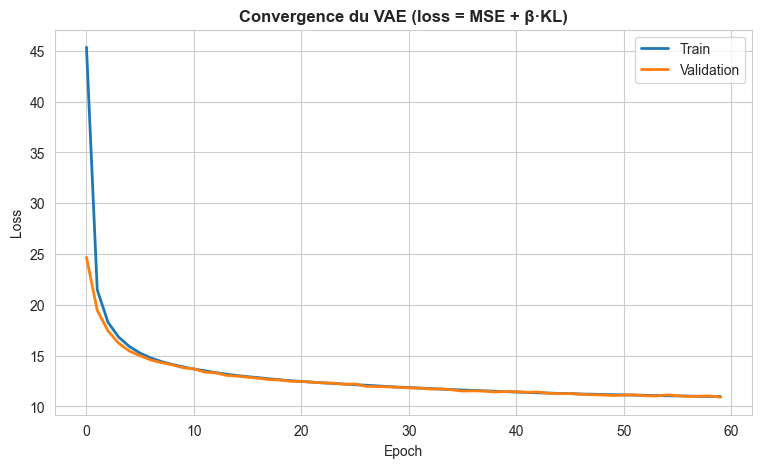

In [ ]:
# Courbe de convergence de la loss
plt.figure(figsize=(9, 5))
plt.plot(hist.history['loss'], label='Train', lw=2)
plt.plot(hist.history['val_loss'], label='Validation', lw=2)
plt.title('Convergence du VAE (loss = MSE + β·KL)', fontweight='bold')
plt.xlabel('Epoch');
plt.ylabel('Loss');
plt.legend()
plt.savefig('02_vae_loss.png', dpi=150, bbox_inches='tight');
plt.show()

## 7. Extraction des Features Latentes

On extrait `μ` (déterministe) et non `z` (stochastique) pour garantir des features stables pour XGBoost. Réduction 115D → 20D (−82.6%).

In [9]:
Z_train, _, _ = encoder.predict(X_train, batch_size=2048, verbose=1)
Z_test,  _, _ = encoder.predict(X_test,  batch_size=2048, verbose=1)
print(f'Latent train {Z_train.shape} | test {Z_test.shape} | réduction {INPUT_DIM}D -> {LATENT_DIM}D')

2759/2759 ━━━━━━━━━━━━━━━━━━━━ 30s 11ms/step
690/690 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step
Latent train (5650084, 20) | test (1412522, 20) | réduction 115D -> 20D


## 8. Visualisation de l'Espace Latent (t-SNE)

Projection 20D → 2D pour visualiser la séparation des classes. La structure circulaire est la signature de la régularisation KL (espace gaussien).

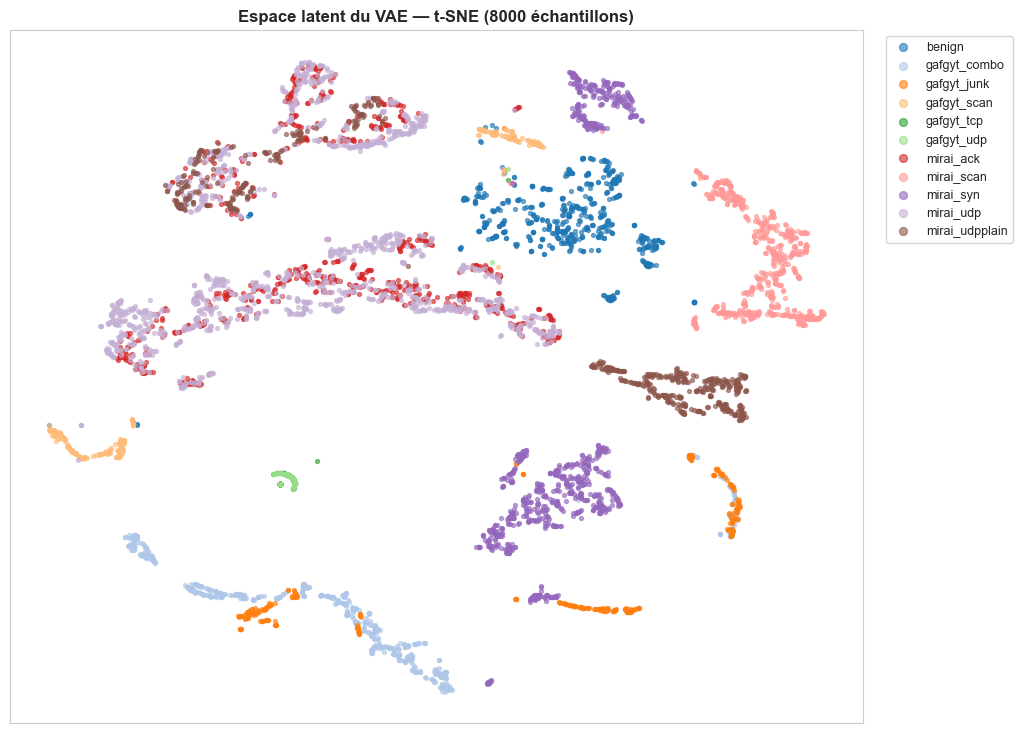

In [ ]:
# Échantillon de 8000 points pour t-SNE (coûteux sur 1.4M points)
n_sample = 8000
sidx = np.random.choice(len(Z_test), n_sample, replace=False)
Z_emb = TSNE(n_components=2, perplexity=30, random_state=42, init='pca').fit_transform(Z_test[sidx])

plt.figure(figsize=(11, 9))
palette = sns.color_palette('tab20', len(le.classes_))
for i, cls in enumerate(le.classes_):
    m = ym_test[sidx] == i
    plt.scatter(Z_emb[m, 0], Z_emb[m, 1], s=8, color=palette[i], label=cls, alpha=0.6)
plt.title(f'Espace latent du VAE — t-SNE ({n_sample} échantillons)', fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', markerscale=2, fontsize=9)
plt.xticks([]);
plt.yticks([])
plt.savefig('03_latent_tsne.png', dpi=150, bbox_inches='tight');
plt.show()

## 9. Classification Binaire (Normal vs Attaque)

XGBoost binaire avec `scale_pos_weight` pour gérer le déséquilibre 7.87% bénin.

In [11]:
spw = (yb_train == 0).sum() / (yb_train == 1).sum()  # poids pour classe minoritaire

xgb_bin = xgb.XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    objective='binary:logistic', scale_pos_weight=spw,
    tree_method='hist', n_jobs=-1, random_state=42, eval_metric='logloss')

t0 = time.time(); xgb_bin.fit(Z_train, yb_train); t_bin = time.time() - t0
t0 = time.time(); yb_pred = xgb_bin.predict(Z_test); tp_bin = time.time() - t0
yb_proba = xgb_bin.predict_proba(Z_test)[:, 1]

print('=== CLASSIFICATION BINAIRE ===')
print(f'Accuracy  : {accuracy_score(yb_test, yb_pred)*100:.4f}%')
print(f'Précision : {precision_score(yb_test, yb_pred)*100:.4f}%')
print(f'Rappel    : {recall_score(yb_test, yb_pred)*100:.4f}%')
print(f'F1-Score  : {f1_score(yb_test, yb_pred)*100:.4f}%')
print(f'Temps     : train {t_bin:.0f}s | prédiction {tp_bin:.1f}s')
print()
print(classification_report(yb_test, yb_pred, target_names=['Bénin', 'Attaque'], digits=4))

=== CLASSIFICATION BINAIRE ===
Accuracy  : 99.9979%
Précision : 99.9993%
Rappel    : 99.9985%
F1-Score  : 99.9989%
Temps     : train 169s | prédiction 7.3s

              precision    recall  f1-score   support

       Bénin     0.9998    0.9999    0.9999    111187
     Attaque     1.0000    1.0000    1.0000   1301335

    accuracy                         1.0000   1412522
   macro avg     0.9999    1.0000    0.9999   1412522
weighted avg     1.0000    1.0000    1.0000   1412522



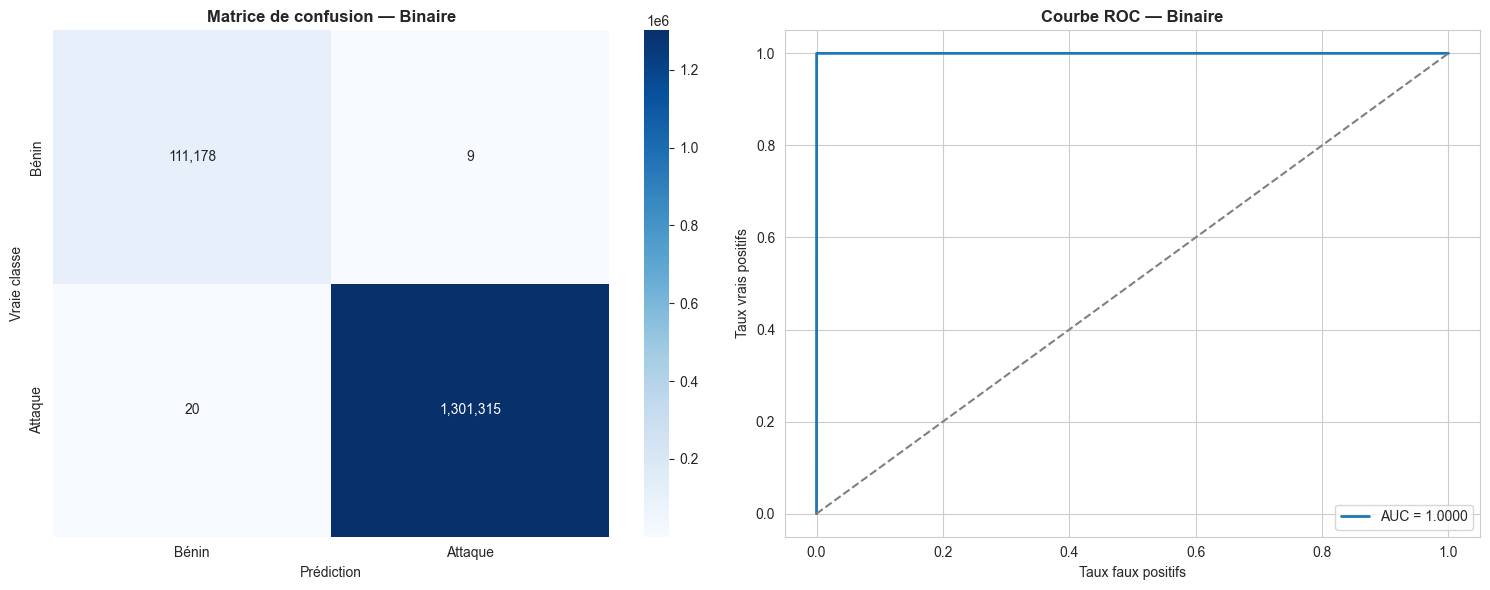

In [ ]:
# Matrice de confusion binaire + courbe ROC
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

cm_bin = confusion_matrix(yb_test, yb_pred)
sns.heatmap(cm_bin, annot=True, fmt=',d', cmap='Blues', ax=ax1,
            xticklabels=['Bénin', 'Attaque'], yticklabels=['Bénin', 'Attaque'])
ax1.set_title('Matrice de confusion — Binaire', fontweight='bold')
ax1.set_ylabel('Vraie classe'); ax1.set_xlabel('Prédiction')

fpr, tpr, _ = roc_curve(yb_test, yb_proba)
ax2.plot(fpr, tpr, lw=2, label=f'AUC = {auc(fpr, tpr):.4f}')
ax2.plot([0, 1], [0, 1], '--', color='gray')
ax2.set_title('Courbe ROC — Binaire', fontweight='bold')
ax2.set_xlabel('Taux faux positifs'); ax2.set_ylabel('Taux vrais positifs');
ax2.legend()

plt.tight_layout(); plt.savefig('04_binaire.png', dpi=150, bbox_inches='tight');
plt.show()

## 10. Classification Multi-Classe (11 classes)

In [13]:
xgb_mul = xgb.XGBClassifier(
    n_estimators=400, max_depth=10, learning_rate=0.08,
    objective='multi:softmax', num_class=len(le.classes_),
    subsample=0.9, colsample_bytree=0.9,
    tree_method='hist', n_jobs=-1, random_state=42, eval_metric='mlogloss')

t0 = time.time(); xgb_mul.fit(Z_train, ym_train); t_mul = time.time() - t0
t0 = time.time(); ym_pred = xgb_mul.predict(Z_test); tp_mul = time.time() - t0

print('=== CLASSIFICATION MULTI-CLASSE ===')
print(f'Accuracy  : {accuracy_score(ym_test, ym_pred)*100:.4f}%')
print(f'Précision : {precision_score(ym_test, ym_pred, average="weighted", zero_division=0)*100:.4f}%')
print(f'Rappel    : {recall_score(ym_test, ym_pred, average="weighted", zero_division=0)*100:.4f}%')
print(f'F1-Score  : {f1_score(ym_test, ym_pred, average="weighted", zero_division=0)*100:.4f}%')
print(f'Temps     : train {vae_time + t_mul:.0f}s (VAE+XGB) | prédiction {tp_mul:.0f}s')
print()
print(classification_report(ym_test, ym_pred, target_names=le.classes_, digits=4))

=== CLASSIFICATION MULTI-CLASSE ===
Accuracy  : 87.8245%
Précision : 93.6116%
Rappel    : 87.8245%
F1-Score  : 83.6529%
Temps     : train 4056s (VAE+XGB) | prédiction 104s

                precision    recall  f1-score   support

        benign     0.9999    0.9999    0.9999    111187
  gafgyt_combo     0.9999    1.0000    0.9999    103031
   gafgyt_junk     1.0000    0.9999    0.9999     52358
   gafgyt_scan     0.9998    0.9999    0.9998     51022
    gafgyt_tcp     1.0000    0.0009    0.0019    171970
    gafgyt_udp     0.5242    1.0000    0.6878    189273
     mirai_ack     0.9998    0.9993    0.9995    128764
    mirai_scan     1.0000    0.9999    0.9999    107596
     mirai_syn     1.0000    1.0000    1.0000    146660
     mirai_udp     0.9995    0.9999    0.9997    246000
mirai_udpplain     0.9999    0.9998    0.9999    104661

      accuracy                         0.8782   1412522
     macro avg     0.9566    0.9090    0.8808   1412522
  weighted avg     0.9361    0.8782    0.

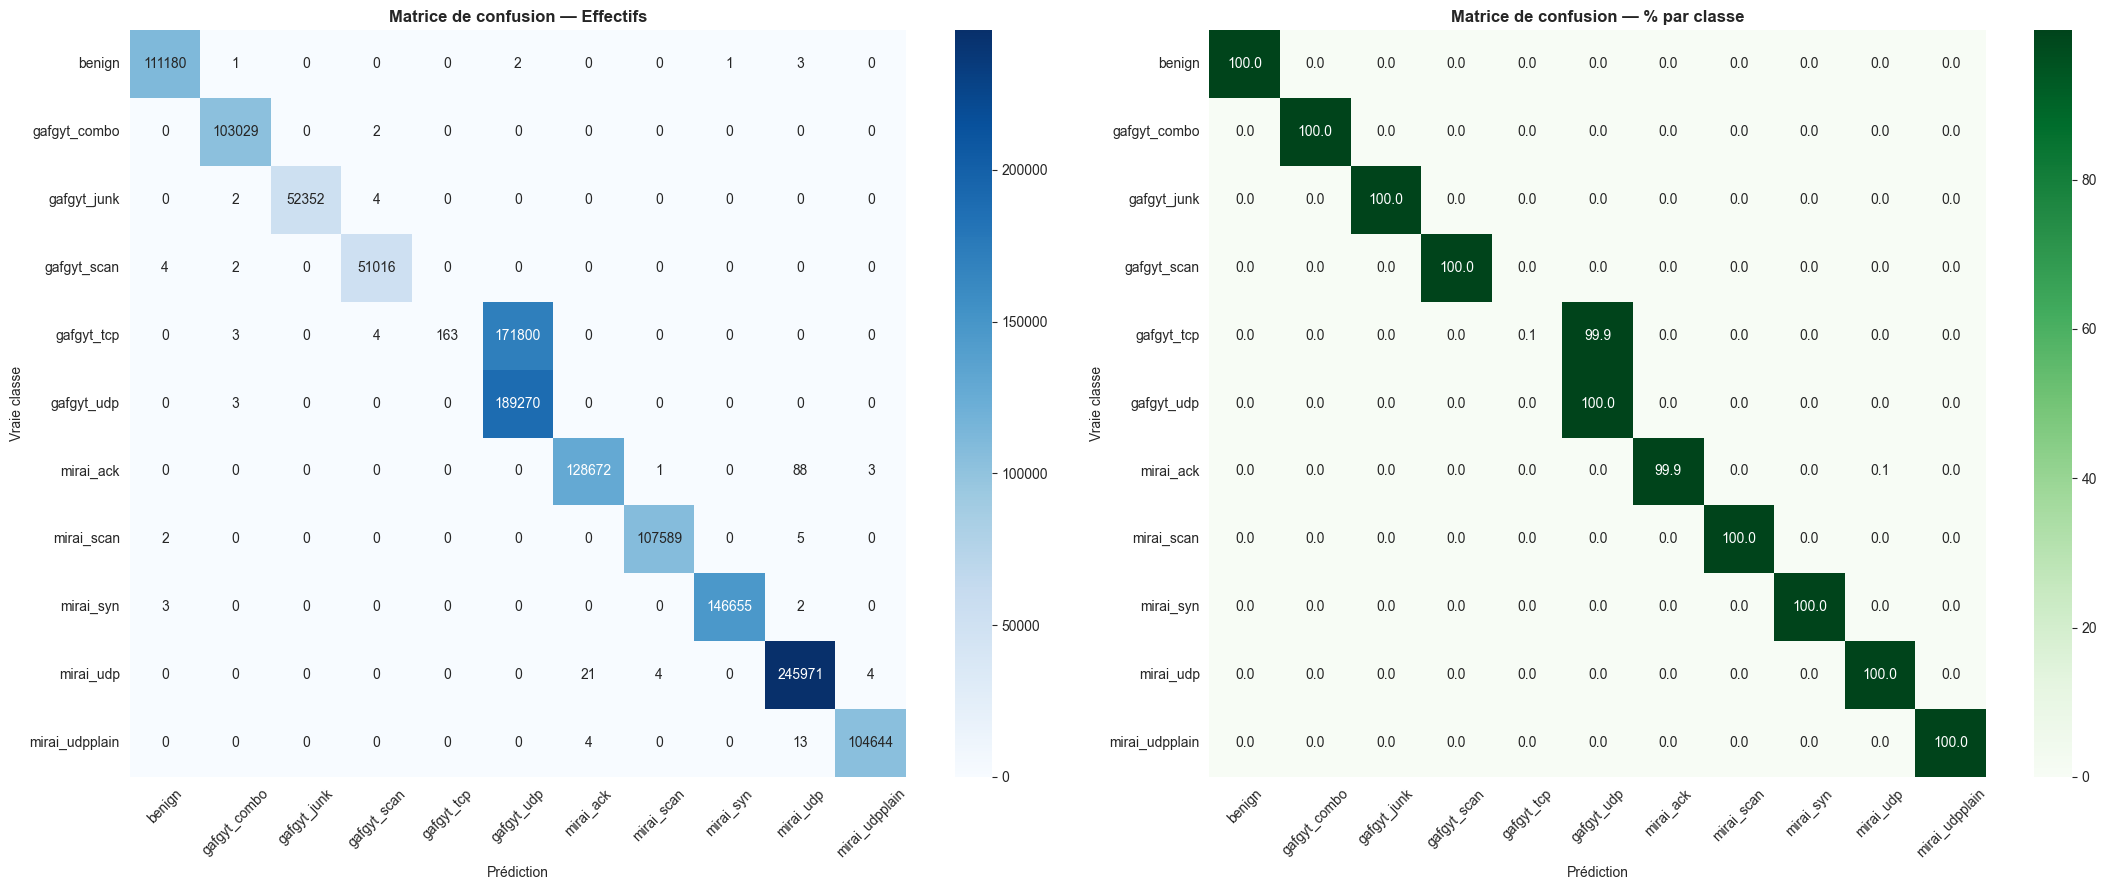

In [14]:
# Matrice de confusion multi-classe (effectifs + pourcentages)
cm  = confusion_matrix(ym_test, ym_pred)
cmn = cm.astype(float) / cm.sum(axis=1)[:, None] * 100

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0].set_title('Matrice de confusion — Effectifs', fontweight='bold')
axes[0].set_ylabel('Vraie classe'); axes[0].set_xlabel('Prédiction')

sns.heatmap(cmn, annot=True, fmt='.1f', cmap='Greens', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[1].set_title('Matrice de confusion — % par classe', fontweight='bold')
axes[1].set_ylabel('Vraie classe'); axes[1].set_xlabel('Prédiction')

for ax in axes: ax.tick_params(axis='x', rotation=45); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.savefig('05_multiclasse.png', dpi=150, bbox_inches='tight'); plt.show()

## 11. Performance par Appareil IoT

Vérification de la généralisation du modèle sur les 9 appareils hétérogènes.

In [15]:
rows = []
for d in np.unique(dev_test):
    m = dev_test == d
    rows.append({
        'Appareil': d.replace('_', ' ')[:30],
        'Flux': m.sum(),
        'Accuracy (%)': round(accuracy_score(ym_test[m], ym_pred[m]) * 100, 4),
        'F1 (%)': round(f1_score(ym_test[m], ym_pred[m], average='weighted', zero_division=0) * 100, 4),
    })
df_dev = pd.DataFrame(rows).sort_values('Accuracy (%)', ascending=False)
print(df_dev.to_string(index=False))
print(f'\nVariance accuracy inter-appareils : {df_dev["Accuracy (%)"].std():.4f}%')

                      Appareil   Flux  Accuracy (%)  F1 (%)
  Philips B120N10 Baby Monitor 219882       91.5732 88.6546
              Danmini Doorbell 203851       90.9782 87.8422
SimpleHome XCS7 1002 WHT Secur 173096       89.7369 86.1529
Provision PT 838 Security Came 167245       89.3211 85.5845
             Ecobee Thermostat 167370       88.5905 84.6873
SimpleHome XCS7 1003 WHT Secur 169960       88.4149 84.4964
Provision PT 737E Security Cam 164995       87.3742 83.2151
     Samsung SNH 1011 N Webcam  75160       73.9263 64.9178
                Ennio Doorbell  70963       71.5049 61.9395

Variance accuracy inter-appareils : 7.5034%


## 12. Importance des Features Latentes

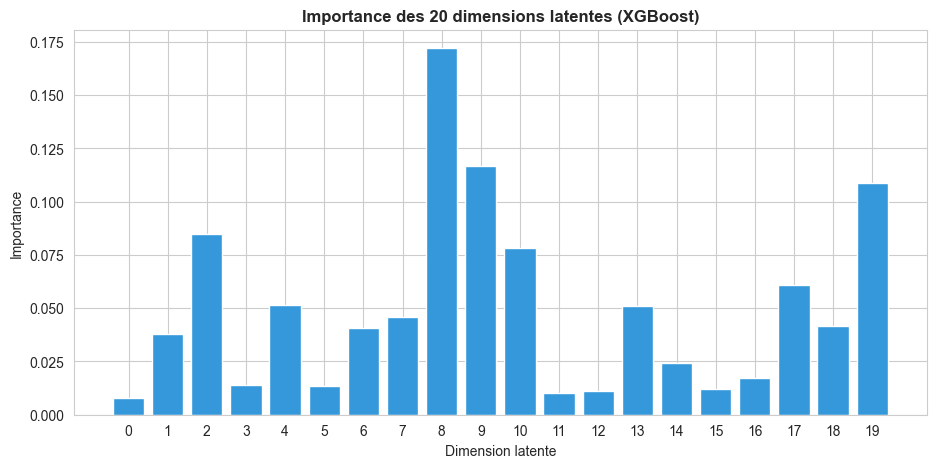

Top 3 dimensions les plus discriminantes : [np.int64(8), np.int64(9), np.int64(19)]


In [16]:
imp = xgb_mul.feature_importances_
plt.figure(figsize=(11, 5))
plt.bar(range(LATENT_DIM), imp, color='#3498db')
plt.title('Importance des 20 dimensions latentes (XGBoost)', fontweight='bold')
plt.xlabel('Dimension latente'); plt.ylabel('Importance')
plt.xticks(range(LATENT_DIM))
plt.savefig('06_feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()

top3 = np.argsort(imp)[::-1][:3]
print(f'Top 3 dimensions les plus discriminantes : {list(top3)}')

## 13. Synthèse des Résultats

In [17]:
synthese = pd.DataFrame({
    'Métrique': ['Accuracy', 'Précision', 'Rappel', 'F1-Score'],
    'Binaire (%)': [
        accuracy_score(yb_test, yb_pred) * 100,
        precision_score(yb_test, yb_pred) * 100,
        recall_score(yb_test, yb_pred) * 100,
        f1_score(yb_test, yb_pred) * 100],
    'Multi-classe (%)': [
        accuracy_score(ym_test, ym_pred) * 100,
        precision_score(ym_test, ym_pred, average='weighted', zero_division=0) * 100,
        recall_score(ym_test, ym_pred, average='weighted', zero_division=0) * 100,
        f1_score(ym_test, ym_pred, average='weighted', zero_division=0) * 100],
}).round(4)

print('SYNTHÈSE — Hybridation VAE + XGBoost')
print(synthese.to_string(index=False))

SYNTHÈSE — Hybridation VAE + XGBoost
 Métrique  Binaire (%)  Multi-classe (%)
 Accuracy      99.9979           87.8245
Précision      99.9993           93.6116
   Rappel      99.9985           87.8245
 F1-Score      99.9989           83.6529


## 14. Sauvegarde des Modèles

In [18]:
encoder.save('vae_encoder.keras')
decoder.save('vae_decoder.keras')
xgb_bin.save_model('xgboost_binary.json')
xgb_mul.save_model('xgboost_multiclass.json')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')
joblib.dump({'lower': lo, 'upper': hi}, 'clip_bounds.pkl')

print('Modèles sauvegardés : vae_encoder, vae_decoder, xgboost_binary,')
print('xgboost_multiclass, scaler, label_encoder, clip_bounds')

Modèles sauvegardés : vae_encoder, vae_decoder, xgboost_binary,
xgboost_multiclass, scaler, label_encoder, clip_bounds
